# 第4回 学習（MCMC）と診断

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。

**この回のゴール**

1. 第3回で組み立てたモデルに、データを学習させる
2. 学習がうまくいったかを、3つの診断（divergence、R-hat と ESS、トレース）で確かめる
3. 学習後のモデルが実際の売上を再現できているかを確かめる（事後予測チェック）

**所要時間**：60分ほど。

> ⚠️ **3章の学習セルは、初回だけ3〜13分かかります。** 作成時の計測では、Google Colab で約3分、C コンパイラのない Windows の PC で約13分でした。結果はファイルに保存するので、2回目以降は数秒で読み込めます。
> 待っている間に、2章と4章の説明を読んでおくのがおすすめです。

> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/04-fit-diagnostics>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします
- Google Colab のときだけ、必要なライブラリを入れます（数分かかります）
- 学習結果の置き場所を決めます（Colab のときは Google ドライブ。初回に許可の画面が出ます）

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- g++（計算を速くする部品）がない環境では、その旨を PyTensor に伝える（WARNING が短くなる） ---
import os, shutil
if shutil.which("g++") is None:
    os.environ["PYTENSOR_FLAGS"] = "cxx="

# --- Colab のときだけ、ライブラリを入れる（数分かかります） ---
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc-marketing==0.19.2", "nutpie==0.16.8"], check=True)

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- 学習結果の置き場所 ---
# Colab は接続が切れるとファイルが消えるので、学習結果は Google ドライブに置く（初回に許可の画面が出ます）。
# ドライブを使いたくないときは USE_DRIVE = False にする（その場合は、回ごとに学習し直します）。
USE_DRIVE = True
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    MODEL_DIR = Path("/content/drive/MyDrive/mmm-pymc/models")
else:
    MODEL_DIR = BASE_DIR / "models"
MODEL_PATH = MODEL_DIR / "mmm_cs1.nc"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


この回で使うライブラリを読み込みます。

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from scipy import stats

from pymc_extras.prior import Prior
from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.multidimensional import MMM

SEED = 42
FAST = {"mode": "NUMBA"}                       # 計算を速くする設定


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


## 1. モデルを組み立て直す（第3回のおさらい）

第3回と同じデータ準備とモデル定義を、まとめて実行します。内容は第3回のノートブックと同じです。

- 7チャネル、祝日フラグ22個、1年周期の季節性
- 学習用 183週（〜2018-02-01）／テスト用 26週
- 事前分布：ベース Normal(0.2, 0.05)、β は HalfNormal(σ = 費用シェア) など

In [3]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])

channel_names = {
    "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
    "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
}
channel_columns = list(channel_names.values())
control_columns = [c for c in raw_df.columns if c.startswith("hldy_")]
date_column = "wk_strt_dt"
target_column = "sales"

data_df = raw_df[[date_column, target_column, *channel_names.keys(), *control_columns]].rename(columns=channel_names)

split_date = pd.to_datetime("2018-02-01")
train_df = data_df[data_df[date_column] <= split_date]
test_df = data_df[data_df[date_column] > split_date]
X_train, y_train = train_df.drop(columns=target_column), train_df[target_column]
X_test, y_test = test_df.drop(columns=target_column), test_df[target_column]

spend_share = X_train[channel_columns].sum() / X_train[channel_columns].sum().sum()

model_config = {
    "intercept": Prior("Normal", mu=0.2, sigma=0.05),
    "saturation_beta": Prior("HalfNormal", sigma=spend_share[channel_columns].to_numpy(), dims="channel"),
    "gamma_control": Prior("Normal", mu=0, sigma=1, dims="control"),
    "gamma_fourier": Prior("Laplace", mu=0, b=1, dims="fourier_mode"),
    "likelihood": Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1)),
}

def build_mmm():
    model = MMM(
        model_config=model_config,
        date_column=date_column,
        target_column=target_column,
        channel_columns=channel_columns,
        control_columns=control_columns,
        adstock=GeometricAdstock(l_max=6),
        saturation=LogisticSaturation(),
        yearly_seasonality=5,
    )
    model.build_model(X_train, y_train)
    model.add_original_scale_contribution_variable(
        var=["channel_contribution", "control_contribution", "intercept_contribution",
             "yearly_seasonality_contribution", "y"]
    )
    return model

print(f"学習用: {len(train_df)} 週 / テスト用: {len(test_df)} 週")

学習用: 183 週 / テスト用: 26 週


## 2. 「学習」とは何をするのか

### 2-1. 事前分布 → 事後分布

第3回で、55個のパラメータに「データを見る前の見込み」（事前分布）を置きました。
学習では、それを実際の売上データと照らし合わせて、「データを見た後の結論」（**事後分布**）に更新します。

$$
\underbrace{p(\theta \mid \text{データ})}_{\text{事後分布}}
\;\propto\;
\underbrace{p(\text{データ} \mid \theta)}_{\text{データへの当てはまり}}
\times
\underbrace{p(\theta)}_{\text{事前分布}}
$$

$\theta$ は55個のパラメータをまとめたものです。「事前に見込みがあり、しかもデータによく当てはまる」パラメータほど、事後分布で高く評価されます。

### 2-2. MCMC：事後分布からサンプルを集める

パラメータが55個もあると、事後分布を式で書き下すことはできません。
そこで、事後分布に従う**パラメータの組を何千個も集めて**、その集まりで分布を表します。この集め方が **MCMC**（マルコフ連鎖モンテカルロ法）です。

たとえるなら、霧のかかった山（事後分布）の形を知るために、登山者を歩き回らせて足あとを記録するようなものです。
登山者は高いところ（ありそうなパラメータ）に長く滞在するので、足あとの密度が山の形を表します。

| 用語 | 意味 | 今回の設定 |
|---|---|---|
| チェーン（chain） | 登山者の人数。別々の場所から独立に歩かせる | 4 |
| チューニング（tune） | 歩き方（歩幅）を調整する準備期間。記録は捨てる | 1,000歩 |
| ドロー（draw） | 実際に記録する歩数 | 1,000歩 |

4人 × 1,000歩 ＝ **4,000組**のパラメータが集まります。

**なぜ複数のチェーンを使うのか**：1人だけだと、山の一部しか歩いていなくても気づけません。
別々の場所から出発した4人が同じ場所を歩き回っていれば、「山全体をとらえた」と考えられます。これが4章の診断の考え方です。

> PyMC が使う歩き方は NUTS という方法で、坂の傾きを使って効率よく進みます。
> この教材では、NUTS の高速版である `nutpie` を指定します（g++ が無い Windows では、指定しないと非常に遅くなります）。

## 3. 学習を実行する

次のセルは、こう動きます。

- 保存済みの学習結果（`models/mmm_cs1.nc`）が**ある**とき → 読み込むだけ（数秒）
- **ない**とき → 学習を実行して保存する（**3〜13分**。進み具合が表示されます）

学習し直したいときは、`models/mmm_cs1.nc` を削除してからこのセルを実行してください（Colab でドライブを使っているときは、Google ドライブの `mmm-pymc/models/` の中にあります）。

In [4]:
if MODEL_PATH.exists():
    mmm = MMM.load(str(MODEL_PATH))
    print("保存済みの学習結果を読み込みました:", MODEL_PATH.name)
else:
    mmm = build_mmm()

    # 学習（MCMC）。3〜13分
    mmm.fit(
        X_train, y_train,
        chains=4, tune=1_000, draws=1_000,
        target_accept=0.9,
        nuts_sampler="nutpie",
        random_seed=SEED,
    )

    # 学習後のモデルで売上を予測しておく（7章で使う）
    mmm.sample_posterior_predictive(X_train, extend_idata=True, combined=True, random_seed=SEED, compile_kwargs=FAST)

    # 準備期間（チューニング）の記録は使わないので消して、保存する
    for group in ["warmup_posterior", "warmup_sample_stats"]:
        if group in mmm.idata.groups():
            del mmm.idata[group]
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    mmm.save(str(MODEL_PATH))

Progress,Draws,Divergences,Step Size,Gradients/Draw
,2000,0,0.16,31
,2000,0,0.14,63
,2000,0,0.15,31
,2000,0,0.15,31


Output()

Sampling: [y]


Output()

In [5]:
posterior = mmm.idata["posterior"]
print("保存ファイル:", MODEL_PATH.name, f"（{MODEL_PATH.stat().st_size / 1e6:.0f} MB）")
print("チェーン数:", posterior.sizes["chain"], "/ 1チェーンあたりのドロー数:", posterior.sizes["draw"])
print("入っているデータ:", list(mmm.idata.groups()))

保存ファイル: mmm_cs1.nc （185 MB）
チェーン数: 4 / 1チェーンあたりのドロー数: 1000
入っているデータ: ['posterior', 'sample_stats', 'observed_data', 'constant_data', 'fit_data', 'posterior_predictive', 'posterior_predictive_constant_data']


> `target_accept=0.9` は「慎重に歩く」設定です（初期値は0.8）。時間は少し増えますが、次の章で説明する divergence が起きにくくなります。

学習結果は `mmm.idata` に入っています。`posterior` が、集めた4,000組のパラメータです。
保存ファイルは約185MBあります（4,000組それぞれについて、週ごと・チャネルごとの貢献も記録しているためです）。

**ここからが大事です。** MCMCは、うまくいかなくてもエラーを出さずに終わります。結果を使う前に、必ず診断します。

## 4. 診断① divergence（発散）

**divergence** は、登山者が急な崖で足を踏み外した回数です。
事後分布の形が複雑で、歩幅が合わない場所があると起きます。多いと、その周辺をきちんと歩けておらず、結果がかたよっているおそれがあります。

- **目安**：0件が理想。数件なら大きな問題にならないことが多い。数十件以上なら対策が必要
- **対策**：`target_accept` を上げる（0.95 など）、事前分布を見直す、モデルを単純にする

In [6]:
n_div = int(mmm.idata["sample_stats"]["diverging"].sum())
n_total = posterior.sizes["chain"] * posterior.sizes["draw"]
print(f"divergence: {n_div} 件 / {n_total} サンプル")

divergence: 0 件 / 4000 サンプル


## 5. 診断② R-hat と ESS

### R-hat（アールハット）

4人の登山者が**同じ場所を歩いたか**を表す数字です。
「チェーン同士のばらつき」と「チェーンの中のばらつき」を比べ、同じなら1.00になります。

- **目安**：1.01以下なら合格。1.05を超えたら、その結果は使わない

### ESS（有効サンプルサイズ）

4,000個のサンプルは、前の1歩に似た値になりがちで、完全にバラバラではありません。
「独立なサンプルに換算すると何個分か」を表すのが ESS です。

- `ess_bulk`：分布の中心（平均など）の推定に効く
- `ess_tail`：分布の端（信用区間の端）の推定に効く
- **目安**：どちらも400以上（チェーン数 × 100）

主なパラメータの一覧を出します。

In [7]:
main_vars = ["intercept_contribution", "y_sigma", "adstock_alpha", "saturation_lam", "saturation_beta"]
summary_main = az.summary(mmm.idata, var_names=main_vars, round_to=3)
summary_main[["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "ess_tail", "r_hat"]]

,mean,sd,hdi_3%,hdi_97%,ess_bulk,ess_tail,r_hat
intercept_contribution,0.189,0.030,0.134,0.246,1593.139,1998.920,1.002
y_sigma,0.107,0.008,0.094,0.122,3208.731,2640.227,1.001
adstock_alpha[DM],0.308,0.215,0.000,0.694,4932.863,2557.486,1.002
adstock_alpha[折込],0.192,0.163,0.000,0.502,5488.804,2184.809,1.003
adstock_alpha[新聞],0.276,0.200,0.000,0.634,5722.125,2079.893,1.001
adstock_alpha[ラジオ],0.266,0.191,0.000,0.608,7056.115,2318.323,1.001
adstock_alpha[TV],0.206,0.162,0.000,0.505,5605.908,2342.994,1.001
adstock_alpha[ソーシャル],0.227,0.186,0.000,0.588,7415.220,2679.637,1.001
adstock_alpha[ディスプレイ],0.227,0.179,0.000,0.555,5819.937,2278.452,1.002
saturation_lam[DM],2.751,1.797,0.161,5.890,2788.386,2483.392,1.001


**表の読み方**

- `mean`・`sd`：事後分布の平均と標準偏差
- `hdi_3%`〜`hdi_97%`：94%の確率でこの範囲にある（信用区間）
- `adstock_alpha[TV]` のように、チャネルごとに1行ずつあります

祝日と季節の係数も含めた、55個すべての最悪値を確認します。

In [8]:
all_vars = main_vars + ["gamma_control", "gamma_fourier"]
summary_all = az.summary(mmm.idata, var_names=all_vars, round_to=3)

print("パラメータの数:", len(summary_all))
print("R-hat の最大値:", summary_all["r_hat"].max())
print("ess_bulk の最小値:", int(summary_all["ess_bulk"].min()))
print("ess_tail の最小値:", int(summary_all["ess_tail"].min()))
print()
print("R-hat が 1.01 を超えるパラメータ:")
print(summary_all.loc[summary_all["r_hat"] > 1.01, ["mean", "ess_bulk", "ess_tail", "r_hat"]])
print()
print("ESS が小さい順に5つ:")
summary_all.sort_values("ess_bulk").head(5)[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]]

パラメータの数: 55
R-hat の最大値: 1.019
ess_bulk の最小値: 533
ess_tail の最小値: 850

R-hat が 1.01 を超えるパラメータ:
                                          mean  ess_bulk  ess_tail  r_hat
gamma_control[hldy_Christmas Day]        0.088   533.329   992.912  1.019
gamma_control[hldy_Day after Christmas]  0.017   538.212  1057.285  1.018

ESS が小さい順に5つ:


,mean,sd,ess_bulk,ess_tail,r_hat
gamma_control[hldy_Christmas Day],0.088,0.706,533.329,992.912,1.019
gamma_control[hldy_Day after Christmas],0.017,0.707,538.212,1057.285,1.018
gamma_control[hldy_Thanksgiving],0.043,0.840,541.425,959.754,1.009
gamma_control[hldy_Pre Thanksgiving],0.066,0.821,586.377,901.784,1.009
gamma_control[hldy_Black Friday],-0.042,0.855,604.951,957.378,1.003


**読み方**

- ESS は全パラメータで400以上（最小533）。合格
- R-hat は55個中53個が1.01以下。**2つだけ約1.02**で、どちらもクリスマス関連の祝日の係数です
- 広告のパラメータ（α・λ・β）はすべて1.01以下で、ESS も十分です

1.05は超えていないので使えない結果ではありませんが、なぜこの2つだけ悪いのかを調べます。ESS が小さい5つも、すべて年末の祝日です。

In [9]:
# 祝日フラグ同士で、中身がまったく同じ列を探す
same_pairs = []
for i, a in enumerate(control_columns):
    for b in control_columns[i + 1:]:
        if (X_train[a] == X_train[b]).all():
            same_pairs.append((a.replace("hldy_", ""), b.replace("hldy_", "")))
pd.DataFrame(same_pairs, columns=["祝日A", "祝日B"])

,祝日A,祝日B
0,Black Friday,Pre Thanksgiving
1,Black Friday,Thanksgiving
2,Christmas Day,Day after Christmas
3,Pre Thanksgiving,Thanksgiving


**原因が分かりました。** 週次データでは、近い日付の祝日が同じ週に入ります。
「Christmas Day」と「Day after Christmas」は毎年同じ週なので、2つの列の中身はまったく同じです。Thanksgiving の前後3つも同じです。

中身が同じ列が2つあると、モデルは「売上の増加をどちらの係数に割り振るか」を決められません。
片方を +0.5、もう片方を −0.5 にしても、合計が同じなら予測は変わらないからです。登山者は「合計が一定」という細長い尾根を行ったり来たりすることになり、歩き回るのに時間がかかります。これが R-hat と ESS を悪くしていました。

**判断**

- 祝日の影響の**合計**は決まっているので、売上の予測や広告効果の推定には大きく影響しません。このまま先に進みます
- ただし「Christmas Day の効果はいくら」と**個別に**読んではいけません
- 実務では、中身が同じ列は1つにまとめます（小課題2）

診断の数字が悪いときは、「どのパラメータが悪いか」を見ると、データやモデルの問題が見つかることがよくあります。

## 6. 診断③ トレースプロット

数字だけでなく、目でも確かめます。**トレースプロット**は、サンプルを順番に並べた図です。

- **左**：事後分布の形。チェーンごとに1本の線。4本が重なっていれば良い
- **右**：歩いた順に値を並べたもの。上下にまんべんなく揺れる「毛虫」のような帯になっていれば良い

悪い例：線が1本だけ離れている、右の図がゆっくり波打つ、階段状に止まる

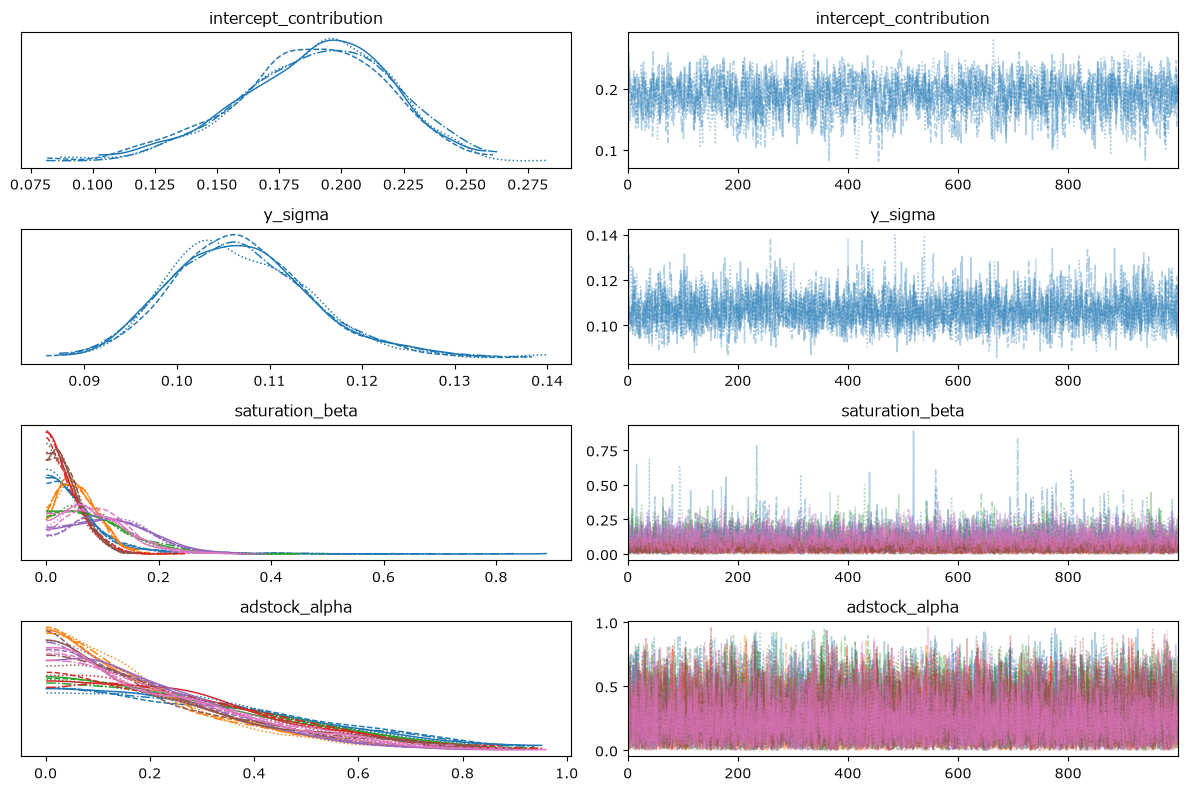

In [10]:
az.plot_trace(
    mmm.idata,
    var_names=["intercept_contribution", "y_sigma", "saturation_beta", "adstock_alpha"],
    compact=True,
    figsize=(12, 8),
)
plt.tight_layout()

**読み方**：`saturation_beta` と `adstock_alpha` は、7チャネル分が色違いで重ねて描かれています。
右側の図はどれも帯状にまんべんなく揺れていて、どこかに止まったり、ゆっくり流れたりしていません。左側の線もチェーン同士で重なっています。

## 7. 🧪 実験：学習が足りないとどうなるか

良い結果だけ見ても、診断のありがたみが分かりません。わざと準備期間と歩数を極端に減らして（tune 20、draw 50）、同じ診断をかけます。

このセルは1分ほどかかります。

In [11]:
mmm_short = build_mmm()
mmm_short.fit(X_train, y_train, chains=4, tune=20, draws=50, nuts_sampler="nutpie", random_seed=1)

summary_short = az.summary(mmm_short.idata, var_names=all_vars, round_to=3)
compare = pd.DataFrame({
    "しっかり学習（tune 1000, draw 1000）": [
        int(mmm.idata["sample_stats"]["diverging"].sum()),
        summary_all["r_hat"].max(), int(summary_all["ess_bulk"].min()),
        int((summary_all["r_hat"] > 1.01).sum()),
    ],
    "学習不足（tune 20, draw 50）": [
        int(mmm_short.idata["sample_stats"]["diverging"].sum()),
        summary_short["r_hat"].max(), int(summary_short["ess_bulk"].min()),
        int((summary_short["r_hat"] > 1.01).sum()),
    ],
}, index=["divergence の件数", "R-hat の最大値", "ess_bulk の最小値", "R-hat が1.01を超えるパラメータの数"])
compare

Only 50 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.


Progress,Draws,Divergences,Step Size,Gradients/Draw
,70,0,0.10,223
,70,0,0.11,63
,70,0,0.11,127
,70,0,0.13,127


Output()

,"しっかり学習（tune 1000, draw 1000）","学習不足（tune 20, draw 50）"
divergence の件数,0.000,0.000
R-hat の最大値,1.019,1.098
ess_bulk の最小値,533.000,78.000
R-hat が1.01を超えるパラメータの数,2.000,34.000


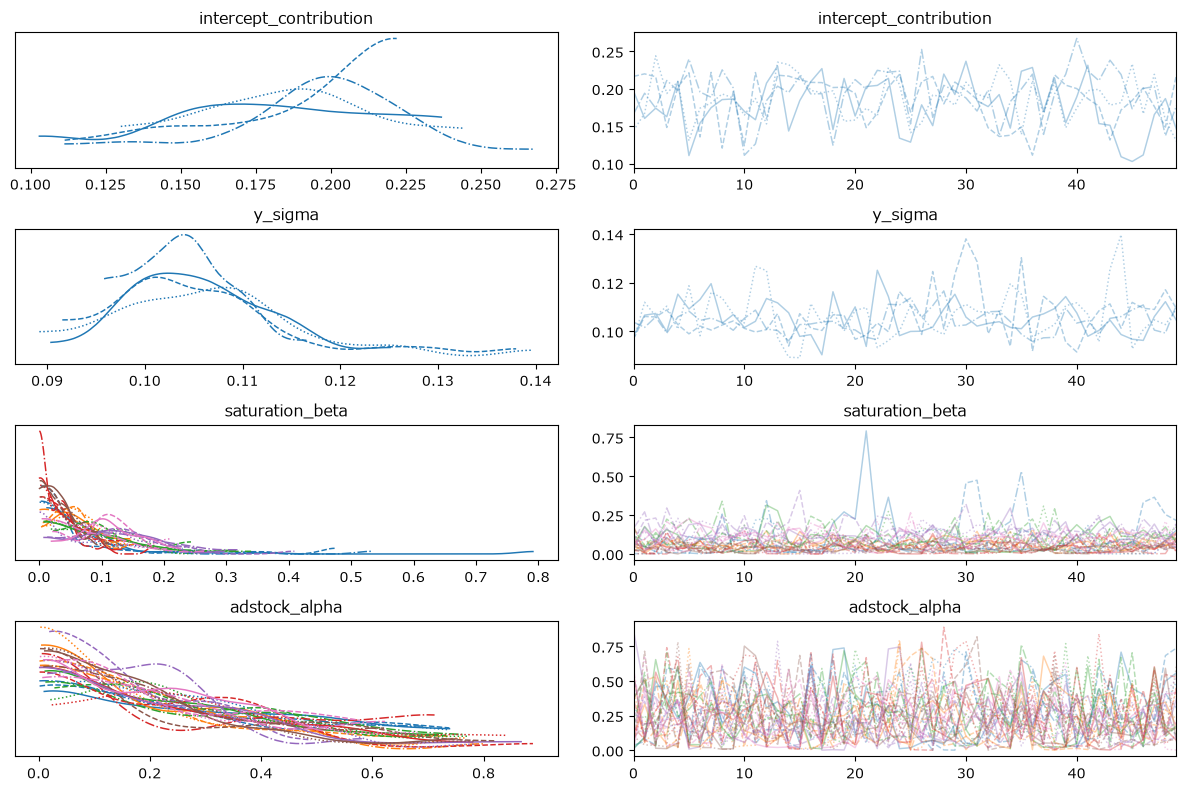

In [12]:
az.plot_trace(
    mmm_short.idata,
    var_names=["intercept_contribution", "y_sigma", "saturation_beta", "adstock_alpha"],
    compact=True,
    figsize=(12, 8),
)
plt.tight_layout()

**読み方**

- R-hat が1.01を超えるパラメータが、2個 → 34個に増えました。ESS の最小値も 533 → 78 です
- トレースプロットの左側で、チェーンごとの線の形がバラバラです。4人の登山者が、まだ別々の景色を見ています
- **divergence は0件のまま**です。divergence だけ見ていると、この学習不足には気づけません

**3つの診断は見ているものが違うので、必ず全部確認します。**

| 診断 | 見ているもの | 合格の目安 |
|---|---|---|
| divergence | 歩けなかった場所がないか | 0件（数件まで） |
| R-hat | チェーン同士が同じ結論か | 1.01以下 |
| ESS | 独立なサンプルが十分あるか | 400以上 |
| トレース | 上の3つを目で確認 | 線が重なり、帯がまんべんなく揺れる |

しかも学習不足のモデルでも、平均値などの数字はそれらしく出てしまいます。診断せずに報告すると、気づかないまま間違った数字を出すことになります。

## 8. 事後予測チェック

診断に合格したので、学習後のモデルが**実際の売上を再現できるか**を確かめます。
第3回の事前予測チェックと同じ図を、学習後のパラメータ4,000組で描きます。

94%の範囲の上端（週の平均）: 1.86 億　※第3回の事前予測では約24億
94%の範囲の幅（週の平均）: 1.47 億
実際の売上が94%の範囲に入った週: 178 / 183（97%）
予測の中央値と実際の売上のずれ（平均）: 25.2%
決定係数 R²（予測の中央値）: 0.69


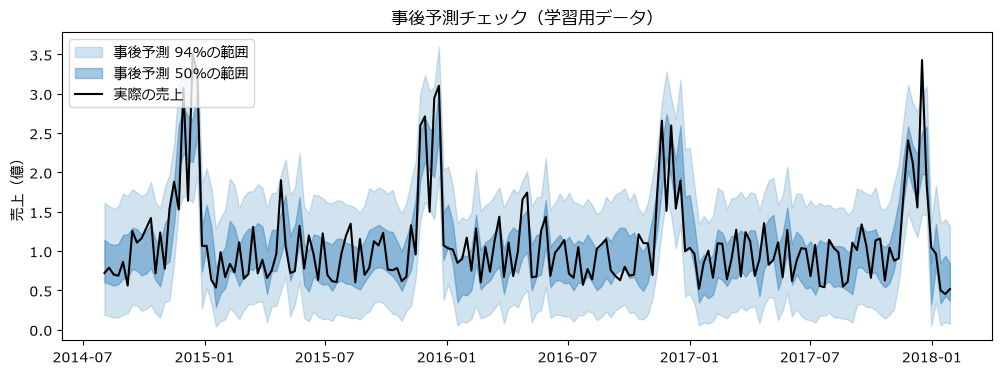

In [13]:
y_post = mmm.idata["posterior_predictive"]["y_original_scale"] / 1e8
dims = [d for d in y_post.dims if d != "date"]          # サンプルの次元（date 以外）
q = y_post.quantile([0.03, 0.25, 0.5, 0.75, 0.97], dim=dims)
dates = X_train[date_column]
actual = y_train.to_numpy() / 1e8

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(dates, q.sel(quantile=0.03), q.sel(quantile=0.97), alpha=0.2, color="C0", label="事後予測 94%の範囲")
ax.fill_between(dates, q.sel(quantile=0.25), q.sel(quantile=0.75), alpha=0.4, color="C0", label="事後予測 50%の範囲")
ax.plot(dates, actual, color="black", label="実際の売上")
ax.set_ylabel("売上（億）")
ax.set_title("事後予測チェック（学習用データ）")
ax.legend(loc="upper left")

low, high, median = q.sel(quantile=0.03).to_numpy(), q.sel(quantile=0.97).to_numpy(), q.sel(quantile=0.5).to_numpy()
inside = (actual >= low) & (actual <= high)
r2 = 1 - ((actual - median) ** 2).sum() / ((actual - actual.mean()) ** 2).sum()
mape = np.mean(np.abs(actual - median) / actual)

print("94%の範囲の上端（週の平均）:", round(float(high.mean()), 2), "億　※第3回の事前予測では約24億")
print("94%の範囲の幅（週の平均）:", round(float((high - low).mean()), 2), "億")
print(f"実際の売上が94%の範囲に入った週: {inside.sum()} / {len(actual)}（{inside.mean():.0%}）")
print(f"予測の中央値と実際の売上のずれ（平均）: {mape:.1%}")
print(f"決定係数 R²（予測の中央値）: {r2:.2f}")

**読み方**

- 第3回の事前予測では、帯の上端は約24億でした。学習後は約1.9億。**データを学習して、予測の範囲が大きくしぼられました**
- 年末の山の位置と高さを、帯がとらえています
- 実際の売上は、183週のうち178週（97%）で94%の範囲に入っています。帯の幅は現実に合っています

**ただし、精度は高くありません。**

- 帯の幅は平均で約1.5億あり、ふだんの週の売上（約1億）より広い
- 予測の中央値と実際の売上のずれは平均25%、決定係数 R² は0.69
- 年末以外の時期の上下（たとえば2015年4月の山）は、とらえきれていません

このモデルの説明変数は、広告7チャネル・祝日・季節だけです。データには値引き（`mrkdn_`）や店舗数（`st_ct`）もありますが、使っていません。
売上を動かす要因がモデルに入っていなければ、その分は「誤差」として残ります。モデルの改良は、ケーススタディ2で扱います。

> これは学習に使ったデータへの当てはまりです。「未来を当てられるか」は別の話で、第6回でテスト用の26週を使って確かめます。

## 9. データは何を教えてくれたか（事前 vs 事後）

最後に、学習で見込みがどう変わったかを見ます。チャネルの効果の大きさ β と、adstock の α について、事前分布と事後分布の「中央値と94%の範囲」を並べます。

,β 事前の中央値,β 事後の中央値,β 範囲の幅 事前,β 範囲の幅 事後,α 事前の中央値,α 事後の中央値,α 範囲の幅 事前,α 範囲の幅 事後
DM,0.303,0.046,0.959,0.256,0.206,0.276,0.679,0.754
折込,0.032,0.054,0.102,0.124,0.206,0.150,0.679,0.573
新聞,0.110,0.080,0.347,0.242,0.206,0.238,0.679,0.697
ラジオ,0.046,0.032,0.146,0.112,0.206,0.232,0.679,0.673
TV,0.067,0.112,0.213,0.245,0.206,0.171,0.679,0.576
ソーシャル,0.035,0.034,0.112,0.102,0.206,0.180,0.679,0.661
ディスプレイ,0.080,0.082,0.253,0.204,0.206,0.188,0.679,0.617


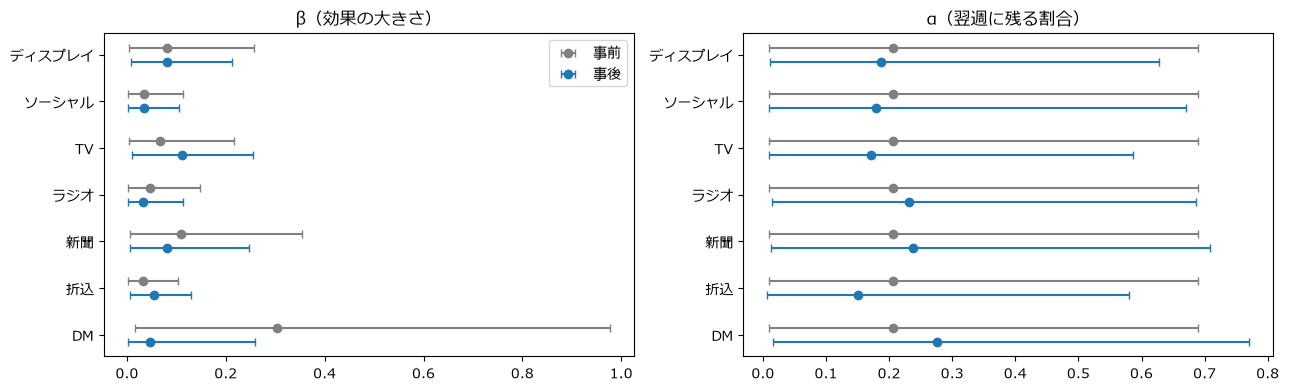

In [14]:
def interval_plot(ax, prior_q, post_q, title):
    # prior_q, post_q：行がチャネル、列が [3%, 50%, 97%]
    ypos = np.arange(len(channel_columns))
    for offset, qv, color, label in [(0.15, prior_q, "gray", "事前"), (-0.15, post_q, "C0", "事後")]:
        ax.errorbar(qv[:, 1], ypos + offset, xerr=[qv[:, 1] - qv[:, 0], qv[:, 2] - qv[:, 1]],
                    fmt="o", color=color, capsize=3, label=label)
    ax.set_yticks(ypos)
    ax.set_yticklabels(channel_columns)
    ax.set_title(title)

probs = [0.03, 0.5, 0.97]
beta_prior = np.array([stats.halfnorm(scale=spend_share[ch]).ppf(probs) for ch in channel_columns])
beta_post = posterior["saturation_beta"].quantile(probs, dim=("chain", "draw")).sel(channel=channel_columns).to_numpy().T
alpha_prior = np.array([stats.beta(1, 3).ppf(probs) for ch in channel_columns])
alpha_post = posterior["adstock_alpha"].quantile(probs, dim=("chain", "draw")).sel(channel=channel_columns).to_numpy().T

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
interval_plot(axes[0], beta_prior, beta_post, "β（効果の大きさ）")
interval_plot(axes[1], alpha_prior, alpha_post, "α（翌週に残る割合）")
axes[0].legend(loc="upper right")
plt.tight_layout()

pd.DataFrame({
    "β 事前の中央値": beta_prior[:, 1], "β 事後の中央値": beta_post[:, 1],
    "β 範囲の幅 事前": beta_prior[:, 2] - beta_prior[:, 0], "β 範囲の幅 事後": beta_post[:, 2] - beta_post[:, 0],
    "α 事前の中央値": alpha_prior[:, 1], "α 事後の中央値": alpha_post[:, 1],
    "α 範囲の幅 事前": alpha_prior[:, 2] - alpha_prior[:, 0], "α 範囲の幅 事後": alpha_post[:, 2] - alpha_post[:, 0],
}, index=channel_columns).round(3)

**読み方**（灰色が事前、青が事後。丸が中央値、横棒が94%の範囲）

**β（効果の大きさ）：データから学べたチャネルがある**

- **DM**：事前の中央値 0.30 → 事後 0.05。範囲の幅も 0.96 → 0.26 に縮みました。
  費用シェア（45%）から「大きな効果もありうる」と見込んでいましたが、データは「そこまで大きくない」と示しています
- **TV**（0.07 → 0.11）と**折込**（0.03 → 0.05）は、事前の見込みより上に動きました
- ソーシャル、ディスプレイ、ラジオは、事前とほとんど変わっていません

**α（翌週に残る割合）：ほとんど学べていない**

- どのチャネルも、事後の範囲は事前（0.01〜0.69）とほぼ同じです
- つまり、このデータからは「広告効果が何週間残るか」は、ほとんど分かりませんでした。事後分布に出ている値は、ほぼ事前分布（Beta(1, 3)）のままです

**事後分布が事前分布とほとんど同じなら、それは「データの結論」ではなく「置いた仮定」です。**
どのパラメータがデータで決まり、どれが仮定のままなのかを区別して報告することが、ベイズ推定を使う側の責任です。

> β はそのまま売上への貢献を表すわけではありません（saturation を通した値にかかる係数です）。
> チャネルごとの貢献額や費用対効果は、第5回で計算します。

## 10. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　別のデータで学習したところ、divergence が200件出ました。R-hat と ESS は合格です。この結果を報告に使ってよいでしょうか。どう対処しますか。

<details>
<summary>答えを見る</summary>

使いません。divergence が多いと、事後分布の一部をきちんと歩けておらず、結果がかたよっているおそれがあります。R-hat が合格でも、4人全員が同じ場所を避けていれば気づけません。

対処の順番の例：

1. `target_accept` を 0.95 や 0.99 に上げて学習し直す（歩幅が小さくなり、時間は増える）
2. 事前分布を見直す。ゆるすぎる事前分布は、歩きにくい形の事後分布を作りやすい
3. モデルを単純にする（チャネルをまとめる、不要な変数を外す）

</details>

**課題2**　5章で、中身が同じ祝日フラグが見つかりました。実務ではどう直しますか。直すと、何が良くなりますか。

<details>
<summary>答えを見る</summary>

中身が同じ列は1つにまとめます。たとえば「Thanksgiving・Pre Thanksgiving・Black Friday」を「感謝祭の週」という1つのフラグにします。

良くなること：

- 係数が1つに決まるので、R-hat と ESS が改善し、学習も速くなる
- 「感謝祭の週の効果」として、係数をそのまま読めるようになる
- パラメータの数が減る（データ183週に対して55個は多め）

学習の前に、説明変数同士の相関を確認する習慣をつけると防げます。広告チャネル同士でも同じ問題が起きます（いつも同時に出稿している2チャネルは、効果を分けられません）。

</details>

**課題3**　9章の結果から、「TVの広告効果は、翌週に17%残ります（α = 0.17）」と報告してよいでしょうか。

<details>
<summary>答えを見る</summary>

そのままでは報告できません。TVの α の94%の範囲は約0.01〜0.59で、事前分布とほとんど同じです。データから学べておらず、0.17 という値は事前分布の形を映しているだけです。

正直な伝え方の例：「今回のデータでは、効果が何週間残るかははっきりしませんでした。残る割合は1%から6割程度まで、幅があります」

残存効果をきちんと知りたい場合は、広告を止める・増やす実験をする、日次データを使う、過去の調査結果を事前分布に入れる、といった方法を提案します。

</details>

**課題4**　報告した相手から「このモデルの数字は信頼できるのですか」と聞かれました。今日の内容から、何を示して説明しますか。

<details>
<summary>答えの例を見る</summary>

1. **計算が正しく終わっていること**：divergence 0件、R-hat と ESS が基準内（祝日の2つは理由を説明できる）
2. **現実を再現できていること**：事後予測チェックの図。年末の山をとらえ、実際の売上の97%が予測の範囲内
3. **限界も伝えること**：ふだんの週のずれは平均25%。残存効果（α）はデータから決まっていない

良い点だけでなく、分かっていない点も先に伝えるほうが、結果として信頼されます。

</details>

## 11. まとめ

- **学習**：事前分布とデータを合わせて事後分布を求める。MCMCは、事後分布に従うパラメータの組を何千個も集める方法
- 今回は4チェーン × 1,000ドロー ＝ 4,000組。`nuts_sampler="nutpie"` を指定する（3〜13分）
- **MCMCは失敗してもエラーを出さない。結果を使う前に必ず診断する**
  - divergence：0件 → 合格
  - R-hat：55個中53個が1.01以下。約1.02の2つは、中身が同じ祝日フラグが原因
  - ESS：最小533 → 合格
  - 診断は見ているものが違うので、全部確認する（学習不足でも divergence は0件だった）
- **事後予測チェック**：予測の範囲は約24億 → 約1.9億にしぼられ、年末の山を再現。ただしふだんの週のずれは平均25%
- **事前 vs 事後**：β はデータで動いた（DMは見込みより小さい）。α はほぼ事前分布のまま
  - 事後が事前と変わらないパラメータは、「データの結論」ではなく「仮定」

学習結果は `models/mmm_cs1.nc` に保存しました。第5回はこれを読み込んで始めます。

**次回（第5回）**：学習結果を読み解きます。チャネルごとの売上への貢献、費用対効果（ROAS）、飽和曲線を、信用区間つきで出します。